# Project 2: Food Delivery ETA Predictor (QuickBite)

**Folder:** `27_pandas/project/` | **Level:** Intermediate | **Time:** 3 hours | **Libraries:** NumPy, pandas, Matplotlib (no scikit-learn needed)

## The business problem

QuickBite delivers food in Indore, Bhopal, Pune and Jaipur. When a customer places an order, the app shows a **promised delivery time**:

- Promise **too short** and the order is late: bad reviews, refunds, lost customers.
- Promise **too long** and customers choose a competitor.

Today the app shows one flat promise for everything. A lunch order from a busy kitchen, a 7 km dinner order in the rain and a 1 km order at 4 pm all get the same promise.

> **How can we predict the delivery time of each order at the moment it is placed, and choose a promise that is short but reliable?**

## What you will build

1. Read **four raw files** (orders, restaurants, riders, weather), clean and merge them
2. Compute **distance** (haversine, vectorized NumPy), **kitchen load** (a fast NumPy trick) and **time/weather features**
3. Avoid **leakage**: the raw file contains columns that only exist *after* the delivery (`pickup_at`)
4. Predict delivery minutes with **ridge regression written from scratch** (`np.linalg.solve`)
5. Split **by time** (train, validation, test weeks) and tune the regularization on validation
6. Turn predictions into a **promise policy** (prediction + safety buffer) and compare with a flat promise

## Skills map

| Skill | Where | Theory notebook |
|---|---|---|
| `read_csv`, parsing, `merge(validate=)` on several keys | loading and joining 4 tables | 03, 11 |
| Mixed date formats, two-pass parsing, `Timedelta` | `placed_at`, durations | 08, 13 |
| Impossible values, swapped coordinates, outliers, flags | GPS errors, 0-minute and 3-hour deliveries | 07, 08 |
| `dt` features, cyclical encoding, `reindex` + `ffill` for gaps | hour, weekday, weather | 13 |
| NumPy: broadcasting, `radians`, `arcsin`, `searchsorted`, `linalg.solve`, `percentile` | distance, kitchen load, ridge | 26_numpy |
| `groupby`, `transform`, `pivot_table`, `cut` | restaurant history, error analysis, heatmap | 10, 12 |
| Matplotlib: `fill_between`, `hexbin`, `imshow`, `boxplot`, dual lines | all the charts | 15 |
| Time-based train/validation/test split, leakage | the split design | 09, 13 |

---
# 0. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

PROJECT = "project_2_food_delivery_eta_predictor"
DATA = Path("data") / PROJECT
FIG = Path("figures") / PROJECT
DATA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 11
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12, "axes.titleweight": "bold",
})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.3


---
# 1. The raw data

As in project 1, the files are **simulated** (reproducible, with real-world problems on purpose). The simulator builds each delivery from realistic parts: kitchen time (more items and a busy kitchen mean more time), waiting for a rider, travel time (distance, vehicle, traffic at meal times, rain) and hand-over, plus random noise and rare "stuck" orders.

You do **not** need to read the simulator. If you have a real delivery dataset you can load it in section 1.2 instead.

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distance in km between points on the Earth (works on whole arrays)."""
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


CITY_CENTERS = {'Indore': (22.7196, 75.8577), 'Bhopal': (23.2599, 77.4126), 'Pune': (18.5204, 73.8567), 'Jaipur': (26.9124, 75.7873)}

def make_quickbite(seed=11, orders_per_day=600):
    """Simulate raw files of a food delivery app: orders, restaurants, riders, hourly weather."""
    rng = np.random.default_rng(seed)
    days = pd.date_range("2026-03-02", periods=98, freq="D")                       # 14 weeks, starts on a Monday
    cities = list(CITY_CENTERS)

    # ---------- restaurants ----------
    n_rest = 160
    rest_city = np.repeat(cities, n_rest // len(cities))
    rest_lat = np.array([CITY_CENTERS[c][0] for c in rest_city]) + rng.normal(0, 0.035, n_rest)
    rest_lon = np.array([CITY_CENTERS[c][1] for c in rest_city]) + rng.normal(0, 0.035, n_rest)
    rest_prep = np.clip(rng.normal(14, 3.5, n_rest), 7, 26)                         # true typical kitchen time (minutes)
    restaurants = pd.DataFrame({
        "restaurant_id": [f"R{i:03d}" for i in range(n_rest)],
        "city": rest_city, "lat": rest_lat.round(5), "lon": rest_lon.round(5),
        "cuisine": rng.choice(["North Indian", "Chinese", "Biryani", "Pizza", "South Indian", "Desserts", "Fast Food"], n_rest),
        "rating": np.clip(rng.normal(4.1, 0.4, n_rest), 2.5, 5).round(1),
        "reported_prep_min": (rest_prep + rng.normal(0, 4, n_rest)).round(0),         # what the restaurant says (noisy)
    })

    # ---------- riders ----------
    n_riders = 400
    riders = pd.DataFrame({
        "rider_id": [f"D{i:04d}" for i in range(n_riders)],
        "vehicle": rng.choice(["bike", "scooter", "ev"], n_riders, p=[0.6, 0.3, 0.1]),
        "experience_months": np.round(rng.gamma(2.0, 8.0, n_riders), 0),
    })
    rider_city = rng.choice(cities, n_riders)

    # ---------- weather (hourly, per city) ----------
    wrows = []
    for city in cities:
        hours = pd.date_range(days[0], periods=98 * 24, freq="h")
        rainy_day = np.repeat(rng.random(98) < np.linspace(0.08, 0.35, 98), 24)
        rain = np.where(rainy_day & (rng.random(len(hours)) < 0.4), rng.gamma(1.5, 2.0, len(hours)), 0.0).round(1)
        temp = 30 + 6 * np.sin((hours.hour.to_numpy() - 9) / 24 * 2 * np.pi) - 0.04 * np.arange(len(hours)) / 24 + rng.normal(0, 1, len(hours))
        wrows.append(pd.DataFrame({"city": city, "hour_ts": hours, "rain_mm": rain, "temp_c": temp.round(1)}))
    weather = pd.concat(wrows, ignore_index=True)

    # ---------- orders ----------
    n = orders_per_day * 98
    day_i = rng.choice(98, n, p=np.where(days.dayofweek >= 5, 1.35, 1.0) / np.where(days.dayofweek >= 5, 1.35, 1.0).sum())
    hour_mix = rng.random(n)
    hour = np.where(hour_mix < 0.38, rng.normal(13, 1.0, n), np.where(hour_mix < 0.82, rng.normal(20.3, 1.3, n), rng.uniform(10, 23.5, n)))
    hour = np.clip(hour, 9.5, 23.8)
    placed = days[day_i] + pd.to_timedelta((hour * 3600).astype(int), unit="s")
    order = np.argsort(placed.to_numpy())
    placed = placed[order]
    day_i = day_i[order]

    r_idx = rng.integers(0, n_rest, n)
    n_items = np.clip(rng.poisson(2.2, n) + 1, 1, 12)
    rider_idx = rng.integers(0, n_riders, n)
    # customer location around the restaurant (up to ~7 km, mostly 1-4 km)
    dist_target = np.clip(rng.gamma(2.2, 1.3, n), 0.3, 9.0)
    angle = rng.uniform(0, 2 * np.pi, n)
    cust_lat = rest_lat[r_idx] + (dist_target * np.cos(angle)) / 111.0
    cust_lon = rest_lon[r_idx] + (dist_target * np.sin(angle)) / (111.0 * np.cos(np.radians(rest_lat[r_idx])))
    dist_km = haversine_km(rest_lat[r_idx], rest_lon[r_idx], cust_lat, cust_lon)

    # kitchen load: orders at the same restaurant in the previous 30 minutes (computed with sorted keys + searchsorted)
    secs = (placed - pd.Timestamp("2026-03-02")).total_seconds().to_numpy()
    key = r_idx * 1e8 + secs
    sk = np.sort(key)
    load = np.searchsorted(sk, key, side="left") - np.searchsorted(sk, key - 1800, side="left")

    hour_of = placed.hour.to_numpy() + placed.minute.to_numpy() / 60
    city_of = rest_city[r_idx]
    # weather at order time
    w = weather.set_index(["city", "hour_ts"])["rain_mm"]
    rain_at = w.reindex(pd.MultiIndex.from_arrays([city_of, placed.floor("h")])).to_numpy()

    vehicle = riders["vehicle"].to_numpy()[rider_idx]
    exp_m = riders["experience_months"].to_numpy()[rider_idx]
    rush = np.exp(-((hour_of - 13) ** 2) / 2.5) + np.exp(-((hour_of - 20.3) ** 2) / 3.5)          # 0..1 around meal times
    traffic = 1 - 0.28 * rush - 0.05 * (placed.dayofweek.to_numpy() >= 5) * rush
    speed = pd.Series(vehicle).map({"bike": 24.0, "scooter": 22.0, "ev": 20.0}).to_numpy() * traffic
    speed = speed * np.where(rain_at > 1.0, 0.78, 1.0) * (1 + 0.004 * np.minimum(exp_m, 30)) * rng.lognormal(0, 0.12, n)

    prep = rest_prep[r_idx] + 1.1 * n_items + 0.9 * load + rng.gamma(2, 1.2, n)
    rider_wait = rng.exponential(2.5 + 4.5 * rush + 2.0 * (rain_at > 1.0), n)
    travel = dist_km / speed * 60
    handover = rng.uniform(2, 6, n)
    total = prep + rider_wait + travel + handover
    stuck = rng.random(n) < 0.012
    total = np.where(stuck, total + rng.uniform(60, 240, n), total)

    delivered = placed + pd.to_timedelta((total * 60).astype(int), unit="s")
    pickup = placed + pd.to_timedelta(((prep + rider_wait) * 60).astype(int), unit="s")

    # ---------- raw, messy export ----------
    fmt = rng.random(n)
    placed_txt = np.where(fmt < 0.85, placed.strftime("%Y-%m-%d %H:%M:%S"), placed.strftime("%d/%m/%Y %I:%M %p"))
    delivered_txt = delivered.strftime("%Y-%m-%d %H:%M:%S").to_numpy().astype(object)
    swap = rng.random(n) < 0.004
    delivered_txt[swap] = placed.strftime("%Y-%m-%d %H:%M:%S").to_numpy()[swap]                    # delivered "at the same time as placed"
    lat, lon = cust_lat.copy(), cust_lon.copy()
    sw = rng.random(n) < 0.005
    lat[sw], lon[sw] = cust_lon[sw], cust_lat[sw]                                                  # swapped coordinates
    zero = rng.random(n) < 0.003
    lat[zero], lon[zero] = 0.0, 0.0                                                                # GPS failure
    value = np.round(n_items * rng.uniform(110, 260, n))
    orders = pd.DataFrame({
        "order_id": [f"O{i:07d}" for i in range(1, n + 1)],
        "placed_at": placed_txt,
        "restaurant_id": restaurants["restaurant_id"].to_numpy()[r_idx],
        "rider_id": riders["rider_id"].to_numpy()[rider_idx],
        "cust_lat": lat.round(5), "cust_lon": lon.round(5),
        "n_items": n_items,
        "order_value": ["Rs." + str(int(v)) if rng.random() < 0.6 else str(int(v)) for v in value],
        "payment_mode": rng.choice(["UPI", "upi", "Cash", "COD", "Card", "card "], n, p=[0.4, 0.1, 0.1, 0.1, 0.2, 0.1]),
        "pickup_at": pickup.strftime("%Y-%m-%d %H:%M:%S"),
        "delivered_at": delivered_txt,
    })
    orders = pd.concat([orders, orders.sample(150, random_state=3)], ignore_index=True)

    weather = weather.copy()
    weather.loc[rng.random(len(weather)) < 0.03, "temp_c"] = -999.0                                # sensor error
    weather = weather.sample(frac=0.97, random_state=4).sort_values(["city", "hour_ts"]).reset_index(drop=True)
    weather["hour_ts"] = weather["hour_ts"].dt.strftime("%Y-%m-%d %H:%M:%S")
    return orders, restaurants, riders, weather

In [3]:
orders_raw, restaurants_raw, riders_raw, weather_raw = make_quickbite(seed=SEED)

orders_raw.to_csv(DATA / "orders_raw.csv", index=False)
restaurants_raw.to_csv(DATA / "restaurants_raw.csv", index=False)
riders_raw.to_csv(DATA / "riders_raw.csv", index=False)
weather_raw.to_csv(DATA / "weather_raw.csv", index=False)
print(sorted(p.name for p in DATA.glob("*_raw.csv")))

['orders_raw.csv', 'restaurants_raw.csv', 'riders_raw.csv', 'weather_raw.csv']


In [4]:
orders = pd.read_csv(DATA / "orders_raw.csv")
restaurants = pd.read_csv(DATA / "restaurants_raw.csv")
riders = pd.read_csv(DATA / "riders_raw.csv")
weather = pd.read_csv(DATA / "weather_raw.csv")

for name, d in [("orders", orders), ("restaurants", restaurants), ("riders", riders), ("weather", weather)]:
    print(f"{name:12s} rows={len(d):6d} columns={d.shape[1]}")

orders       rows= 58950 columns=11
restaurants  rows=   160 columns=7
riders       rows=   400 columns=3
weather      rows=  9126 columns=4


## Data dictionary

| Table | Column | Meaning | Known when the order is placed? |
|---|---|---|---|
| orders | `order_id`, `placed_at` | order and the time it was placed (mixed text formats) | yes |
| | `restaurant_id`, `rider_id` | restaurant, and the rider who delivered | restaurant yes, rider **assigned later** |
| | `cust_lat`, `cust_lon` | delivery location | yes |
| | `n_items`, `order_value`, `payment_mode` | basket | yes |
| | `pickup_at` | when the rider picked up the food | **NO (future)** |
| | `delivered_at` | when the food arrived | **NO (this is our target)** |
| restaurants | `restaurant_id`, `city`, `lat`, `lon`, `cuisine`, `rating`, `reported_prep_min` | restaurant details | yes |
| riders | `rider_id`, `vehicle`, `experience_months` | rider details | after assignment |
| weather | `city`, `hour_ts`, `rain_mm`, `temp_c` | hourly weather per city | yes (forecast or current) |

> **Target:** `delivery_minutes = delivered_at - placed_at`.
> **Leakage warning:** `pickup_at` is a perfect hint for the delivery time but it does not exist when the customer sees the promise. A model using it would look brilliant and be useless.

A rider is assigned a little after the order. To keep the project simple we treat the rider as known (in production you would use the average of nearby riders).

---
# 2. Look before you clean (chapter 04)

In [5]:
orders.head(3).T

,0,1,2
order_id,O0000001,O0000002,O0000003
placed_at,2026-03-02 10:03:09,2026-03-02 10:04:25,2026-03-02 10:06:48
restaurant_id,R112,R054,R128
rider_id,D0016,D0298,D0024
cust_lat,18.56436,23.32454,26.89179
cust_lon,73.77386,77.39464,75.75201
n_items,3,3,5
order_value,Rs.343,Rs.357,1079
payment_mode,Cash,upi,card
pickup_at,2026-03-02 10:18:58,2026-03-02 10:26:17,2026-03-02 10:26:15


In [6]:
def quick_look(df, name):
    rep = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
    print(f"--- {name}: {df.shape[0]} rows, {df.duplicated().sum()} exact duplicate rows ---")
    return rep

quick_look(orders, "orders")

--- orders: 58950 rows, 150 exact duplicate rows ---


,dtype,missing,unique
order_id,str,0,58800
placed_at,str,0,57707
restaurant_id,str,0,160
rider_id,str,0,400
cust_lat,float64,0,37532
cust_lon,float64,0,34298
n_items,int64,0,11
order_value,str,0,3207
payment_mode,str,0,6
pickup_at,str,0,58242


In [7]:
print(orders["payment_mode"].value_counts().to_dict())
print("placed_at text lengths:", orders["placed_at"].str.len().value_counts().to_dict())
print(orders[["cust_lat", "cust_lon"]].describe().round(2))

{'UPI': 23609, 'Card': 11852, 'Cash': 5957, 'upi': 5929, 'card ': 5866, 'COD': 5737}
placed_at text lengths: {19: 58950}
       cust_lat  cust_lon
count  58950.00  58950.00
mean      23.05     75.23
std        4.96      5.75
min        0.00      0.00
25%       18.64     73.93
50%       23.17     75.82
75%       26.82     77.27
max       77.49     77.56


In [8]:
print(weather["temp_c"].describe().round(1))
print("hours per city:", weather.groupby("city").size().to_dict(), "(a full 98 days has", 98 * 24, ")")

count    9126.0
mean       -0.7
std       169.3
min      -999.0
25%        23.8
50%        27.7
75%        31.9
max        38.4
Name: temp_c, dtype: float64
hours per city: {'Bhopal': 2264, 'Indore': 2284, 'Jaipur': 2288, 'Pune': 2290} (a full 98 days has 2352 )


### Problems we found

| Table | Problem | Fix |
|---|---|---|
| orders | 150 duplicate rows | `drop_duplicates("order_id")` |
| orders | `placed_at` in two formats (`2026-03-02 10:03:09` and `02/03/2026 10:03 AM`) | two-pass parsing |
| orders | `order_value` text (`Rs.343`) | numeric |
| orders | payment mode spelled many ways (`upi`, `card `, `COD`) | normalise |
| orders | coordinates **swapped** (latitude 75, longitude 22) and **zeros** (GPS failure) | swap back, or drop |
| orders | some `delivered_at` equal to `placed_at` (0 minutes) | invalid, drop |
| orders | a few deliveries take 2 to 5 hours | "stuck" orders: flag, keep out of the ETA model |
| weather | `temp_c = -999` (sensor error), missing hours | NaN, then fill from neighbouring hours |

**Say it in an interview:** "I listed every data problem in a table with its fix before writing any cleaning code."

---
# 3. Cleaning (chapters 07, 08, 13)

In [9]:
log = []
def note(table, step, n):
    log.append({"table": table, "step": step, "rows_or_values": int(n)})

o = orders.copy()

# 1. duplicates
before = len(o)
o = o.drop_duplicates(subset="order_id").reset_index(drop=True)
note("orders", "duplicate orders removed", before - len(o))

# 2. timestamps: two-pass parsing (ISO first, then day-first with AM/PM), chapter 08
text = o["placed_at"].str.strip()
iso = pd.to_datetime(text, format="ISO8601", errors="coerce")
other = pd.to_datetime(text.where(iso.isna()), format="%d/%m/%Y %I:%M %p", errors="coerce")
o["placed_at"] = iso.fillna(other)
note("orders", "placed_at parsed from the second format", iso.isna().sum())
assert o["placed_at"].notna().all()
o["pickup_at"] = pd.to_datetime(o["pickup_at"])
o["delivered_at"] = pd.to_datetime(o["delivered_at"])

# 3. order value and payment mode
o["order_value"] = pd.to_numeric(o["order_value"].str.replace(r"[^\d]", "", regex=True))
o["payment_mode"] = o["payment_mode"].str.strip().str.lower().replace({"cod": "cash"})

# 4. coordinates: swapped (latitude should be below 40 and longitude above 60 in our cities) and GPS zeros
swapped = o["cust_lat"] > 40
o.loc[swapped, ["cust_lat", "cust_lon"]] = o.loc[swapped, ["cust_lon", "cust_lat"]].to_numpy()
note("orders", "swapped coordinates fixed", swapped.sum())
gps_fail = (o["cust_lat"].abs() < 1) & (o["cust_lon"].abs() < 1)
note("orders", "GPS failure rows (0,0) dropped", gps_fail.sum())
o = o[~gps_fail]

# 5. the target and impossible durations
o["delivery_minutes"] = (o["delivered_at"] - o["placed_at"]).dt.total_seconds() / 60
bad_time = o["delivery_minutes"] <= 5
note("orders", "delivery time <= 5 min (invalid) dropped", bad_time.sum())
o = o[~bad_time]

# 6. stuck orders: flag, do not silently delete
o["is_stuck"] = o["delivery_minutes"] > 120
note("orders", "stuck orders (> 120 min) flagged", o["is_stuck"].sum())

# ----- weather -----
w = weather.copy()
w["hour_ts"] = pd.to_datetime(w["hour_ts"])
sensor_error = w["temp_c"] < -100
w.loc[sensor_error, "temp_c"] = np.nan
note("weather", "temperature sensor errors -> NaN", sensor_error.sum())

full_grid = pd.date_range(w["hour_ts"].min(), w["hour_ts"].max(), freq="h")
filled = []
for city, g in w.groupby("city"):
    g = g.set_index("hour_ts").reindex(full_grid)                    # bring back the missing hours
    g["city"] = city
    g["rain_mm"] = g["rain_mm"].ffill(limit=3)                       # short gaps only
    g["temp_c"] = g["temp_c"].interpolate(limit=6)
    filled.append(g.rename_axis("hour_ts").reset_index())
w = pd.concat(filled, ignore_index=True)
note("weather", "hours rebuilt to a complete hourly calendar", len(w) - len(weather))

pd.DataFrame(log)

,table,step,rows_or_values
0,orders,duplicate orders removed,150
1,orders,placed_at parsed from the second format,8755
2,orders,swapped coordinates fixed,302
3,orders,"GPS failure rows (0,0) dropped",178
4,orders,delivery time <= 5 min (invalid) dropped,246
5,orders,stuck orders (> 120 min) flagged,627
6,weather,temperature sensor errors -> NaN,255
7,weather,hours rebuilt to a complete hourly calendar,282


count    58376.0
mean        41.2
std         20.2
min         14.4
25%         32.5
50%         38.0
75%         45.2
max        301.7
Name: delivery_minutes, dtype: float64
share of stuck orders: 1.07 %


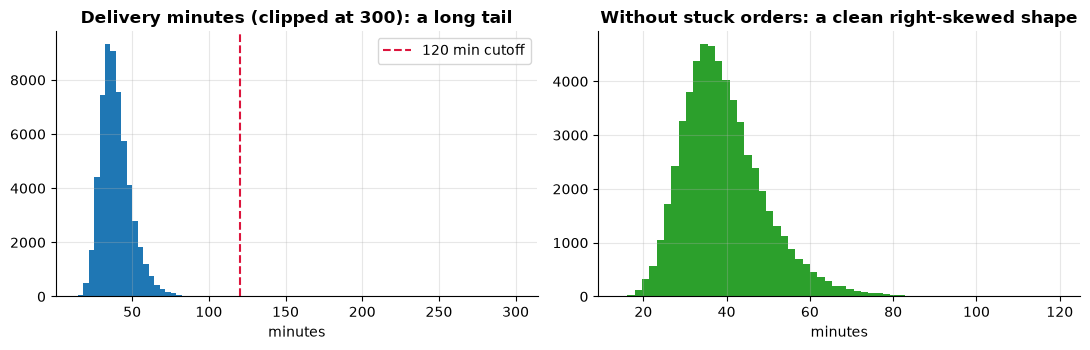

In [10]:
# The stuck orders: how different are they from normal deliveries? (why we keep them out of the ETA model)
print(o["delivery_minutes"].describe().round(1))
print("share of stuck orders:", round(o["is_stuck"].mean() * 100, 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(o["delivery_minutes"].clip(upper=300), bins=80, color="#1f77b4")
axes[0].axvline(120, color="crimson", linestyle="--", label="120 min cutoff")
axes[0].set_title("Delivery minutes (clipped at 300): a long tail"); axes[0].legend()
axes[1].hist(o.loc[~o["is_stuck"], "delivery_minutes"], bins=60, color="#2ca02c")
axes[1].set_title("Without stuck orders: a clean right-skewed shape")
for ax in axes: ax.set_xlabel("minutes")
plt.tight_layout(); plt.show()
savefig(fig, "01_delivery_time_distribution")

**Why not just delete the stuck orders?** Because they are a different problem (accident, wrong address, phone off), not "slow delivery". We keep them in a **flag** and handle them with a separate process (alert the support team). The ETA model is trained on **normal** deliveries, otherwise a handful of 4-hour orders would pull every prediction upwards.

## 3.2 Merge the tables (chapter 11)

Orders get their restaurant, rider and the weather of that hour. `validate="many_to_one"` guarantees that no order is duplicated by a bad key.

In [11]:
n_before = len(o)

df = (
    o.merge(restaurants.rename(columns={"city": "city", "lat": "rest_lat", "lon": "rest_lon", "rating": "rest_rating"}),
            on="restaurant_id", how="left", validate="many_to_one")
     .merge(riders, on="rider_id", how="left", validate="many_to_one")
)
df["hour_ts"] = df["placed_at"].dt.floor("h")
df = df.merge(w[["city", "hour_ts", "rain_mm", "temp_c"]], on=["city", "hour_ts"], how="left", validate="many_to_one")

assert len(df) == n_before, "a merge changed the number of orders"
print(df.shape, "| orders without weather:", int(df["rain_mm"].isna().sum()), "| without restaurant:", int(df["city"].isna().sum()))
df = df.sort_values("placed_at").reset_index(drop=True)
df[["order_id", "placed_at", "city", "rest_lat", "cust_lat", "vehicle", "rain_mm", "delivery_minutes"]].head(3)

(58376, 24) | orders without weather: 0 | without restaurant: 0


,order_id,placed_at,city,rest_lat,cust_lat,vehicle,rain_mm,delivery_minutes
0,O0000001,2026-03-02 10:03:09,Pune,18.59418,18.56436,scooter,0.0,32.316667
1,O0000002,2026-03-02 10:04:25,Bhopal,23.29335,23.32454,bike,0.0,34.166667
2,O0000003,2026-03-02 10:06:48,Jaipur,26.89770,26.89179,bike,0.0,28.816667


---
# 4. Feature engineering

Only information that is **known at the moment the order is placed** (no `pickup_at`, no `delivered_at`).

## 4.1 Distance with haversine (vectorized NumPy)

The distance between two GPS points on a sphere: `d = 2R * arcsin( sqrt( sin²(Δlat/2) + cos(lat1) cos(lat2) sin²(Δlon/2) ) )`. One formula, applied to **all rows at once** (no loop).

In [12]:
df["distance_km"] = haversine_km(df["rest_lat"].to_numpy(), df["rest_lon"].to_numpy(),
                                 df["cust_lat"].to_numpy(), df["cust_lon"].to_numpy())
print(df["distance_km"].describe().round(2))
assert df["distance_km"].between(0.05, 15).all(), "unrealistic distances: check the coordinates"

count    58376.00
mean         2.85
std          1.87
min          0.30
25%          1.45
50%          2.46
75%          3.84
max          9.02
Name: distance_km, dtype: float64


## 4.2 Kitchen load: orders at the same restaurant in the last 30 minutes

A busy kitchen is slower. The slow way is a loop over every order. The fast NumPy way: build **one sortable key per order** (`restaurant * big_number + seconds`), sort once, and let **`np.searchsorted`** count how many keys fall inside the window.

In [13]:
def past_count(group_codes, seconds, window):
    """For every row: how many rows of the same group happened in the previous `window` seconds (strictly earlier, itself excluded)."""
    key = group_codes * 1e8 + seconds
    order = np.argsort(key)
    sk = key[order]
    counts_sorted = np.searchsorted(sk, sk, side="left") - np.searchsorted(sk, sk - window, side="left")
    out = np.empty(len(key))
    out[order] = counts_sorted
    return out

secs = (df["placed_at"] - df["placed_at"].min()).dt.total_seconds().to_numpy()
rest_code = df["restaurant_id"].astype("category").cat.codes.to_numpy()
city_code = df["city"].astype("category").cat.codes.to_numpy()

df["kitchen_load_30m"] = past_count(rest_code, secs, 1800)
df["city_orders_15m"] = past_count(city_code, secs, 900)

# Prove that the fast method is right by comparing it with a slow loop on a sample
rows = np.random.default_rng(0).choice(len(df), 300, replace=False)
slow = [((rest_code == rest_code[i]) & (secs < secs[i]) & (secs >= secs[i] - 1800)).sum() for i in rows]
assert (df["kitchen_load_30m"].to_numpy()[rows] == np.array(slow)).all()
print("fast method == slow loop on 300 sample rows")
df[["kitchen_load_30m", "city_orders_15m"]].describe().round(1)

fast method == slow loop on 300 sample rows


,kitchen_load_30m,city_orders_15m
count,58376.0,58376.0
mean,0.2,4.1
std,0.5,2.7
min,0.0,0.0
25%,0.0,2.0
50%,0.0,4.0
75%,0.0,6.0
max,4.0,18.0


## 4.3 Time, weather, rider and basket features

In [14]:
t = df["placed_at"].dt
df["hour"] = t.hour
df["minute_of_day"] = t.hour * 60 + t.minute
df["dow"] = t.dayofweek
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["is_lunch"] = df["hour"].between(12, 14).astype(int)
df["is_dinner"] = df["hour"].between(19, 22).astype(int)

# cyclical encoding: 23:00 and 00:00 are neighbours (chapter 13)
df["hour_sin"] = np.sin(2 * np.pi * df["minute_of_day"] / 1440)
df["hour_cos"] = np.cos(2 * np.pi * df["minute_of_day"] / 1440)

df["is_raining"] = (df["rain_mm"].fillna(0) > 1).astype(int)
df["rain_mm"] = df["rain_mm"].fillna(0)
df["temp_c"] = df["temp_c"].fillna(df["temp_c"].median())

df["is_ev"] = (df["vehicle"] == "ev").astype(int)
df["is_scooter"] = (df["vehicle"] == "scooter").astype(int)
df["exp_months_capped"] = df["experience_months"].clip(upper=30)

# interactions: the effect of distance is different when it rains or at a busy time
df["dist_x_rain"] = df["distance_km"] * df["is_raining"]
df["dist_x_peak"] = df["distance_km"] * (df["is_lunch"] | df["is_dinner"]).astype(int)
df["items_x_load"] = df["n_items"] * df["kitchen_load_30m"]
df["dist_sq"] = df["distance_km"] ** 2

## 4.4 Time-based split

Weeks 1 to 10 = **train**, weeks 11 to 12 = **validation** (to choose settings), weeks 13 to 14 = **test** (touched once at the end). Stuck orders are excluded from model training and evaluation.

In [15]:
start = df["placed_at"].min().normalize()
week = ((df["placed_at"] - start).dt.days // 7) + 1
df["week"] = week

model_df = df[~df["is_stuck"]].copy()
train = model_df[model_df["week"] <= 10].copy()
valid = model_df[model_df["week"].between(11, 12)].copy()
test = model_df[model_df["week"] >= 13].copy()

split = pd.DataFrame({"rows": [len(train), len(valid), len(test)],
                      "from": [d["placed_at"].min().date() for d in (train, valid, test)],
                      "to": [d["placed_at"].max().date() for d in (train, valid, test)],
                      "mean_minutes": [round(d["delivery_minutes"].mean(), 1) for d in (train, valid, test)]},
                     index=["train", "validation", "test"])
split

,rows,from,to,mean_minutes
train,41195,2026-03-02,2026-05-10,39.4
validation,8213,2026-05-11,2026-05-24,39.7
test,8341,2026-05-25,2026-06-07,39.4


In [16]:
# Restaurant history feature (target encoding), learned from TRAIN only.
# For train rows we use leave-one-out (the row's own delivery time is removed), otherwise the feature would contain the answer.
g_sum = train.groupby("restaurant_id")["delivery_minutes"].transform("sum")
g_cnt = train.groupby("restaurant_id")["delivery_minutes"].transform("count")
global_mean = train["delivery_minutes"].mean()
SMOOTH = 20

def smooth(sum_, cnt):
    return (sum_ + SMOOTH * global_mean) / (cnt + SMOOTH)

train["rest_hist_min"] = smooth(g_sum - train["delivery_minutes"], g_cnt - 1)                    # leave-one-out

rest_stats = train.groupby("restaurant_id")["delivery_minutes"].agg(["sum", "count"])
rest_table = smooth(rest_stats["sum"], rest_stats["count"])
for part in (valid, test):
    part["rest_hist_min"] = part["restaurant_id"].map(rest_table).fillna(global_mean)

print("restaurant history feature, std of train / valid / test:",
      round(train["rest_hist_min"].std(), 2), round(valid["rest_hist_min"].std(), 2), round(test["rest_hist_min"].std(), 2))

restaurant history feature, std of train / valid / test: 3.18 3.17 3.19


**Say it in an interview:** "Features use only what is known when the order is placed. I excluded `pickup_at` as a leaky column. Distance is a vectorized haversine, kitchen load uses sorted keys and `searchsorted` instead of a Python loop (I checked it against a slow loop). Restaurant history is learned from the training weeks only, with leave-one-out for the training rows."

---
# 5. Exploratory analysis (training weeks only)

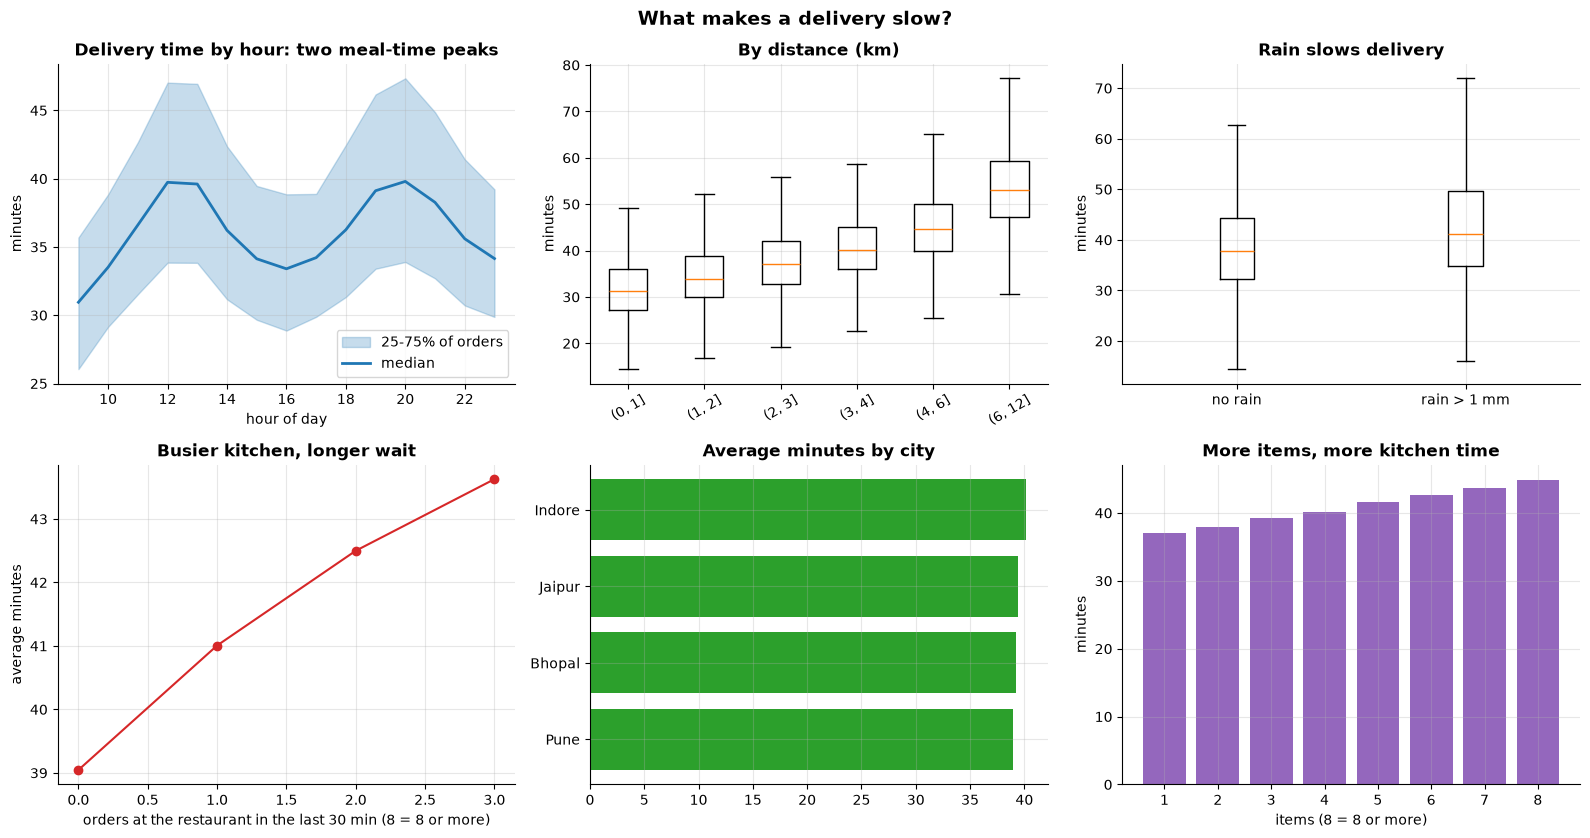

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))

# 1. by hour: median with the 25-75% band
by_hour = train.groupby("hour")["delivery_minutes"].quantile([0.25, 0.5, 0.75]).unstack()
axes[0, 0].fill_between(by_hour.index, by_hour[0.25], by_hour[0.75], alpha=0.25, color="#1f77b4", label="25-75% of orders")
axes[0, 0].plot(by_hour.index, by_hour[0.5], color="#1f77b4", linewidth=2, label="median")
axes[0, 0].set_title("Delivery time by hour: two meal-time peaks"); axes[0, 0].set_xlabel("hour of day"); axes[0, 0].legend()

# 2. by distance band
bands = pd.cut(train["distance_km"], [0, 1, 2, 3, 4, 6, 12])
groups = [g["delivery_minutes"].to_numpy() for _, g in train.groupby(bands, observed=True)]
axes[0, 1].boxplot(groups, tick_labels=[str(b) for b in sorted(bands.dropna().unique())], showfliers=False)
axes[0, 1].set_title("By distance (km)"); axes[0, 1].tick_params(axis="x", rotation=30)

# 3. rain
rain_groups = [train.loc[train["is_raining"] == 0, "delivery_minutes"], train.loc[train["is_raining"] == 1, "delivery_minutes"]]
axes[0, 2].boxplot(rain_groups, tick_labels=["no rain", "rain > 1 mm"], showfliers=False)
axes[0, 2].set_title("Rain slows delivery")

# 4. kitchen load
load = train.groupby(train["kitchen_load_30m"].clip(upper=8))["delivery_minutes"].agg(["mean", "count"])
axes[1, 0].plot(load.index, load["mean"], marker="o", color="#d62728")
axes[1, 0].set_title("Busier kitchen, longer wait"); axes[1, 0].set_xlabel("orders at the restaurant in the last 30 min (8 = 8 or more)")
axes[1, 0].set_ylabel("average minutes")

# 5. by city
city = train.groupby("city")["delivery_minutes"].mean().sort_values()
axes[1, 1].barh(city.index, city.values, color="#2ca02c")
axes[1, 1].set_title("Average minutes by city")

# 6. basket size
items = train.groupby(train["n_items"].clip(upper=8))["delivery_minutes"].mean()
axes[1, 2].bar(items.index.astype(str), items.values, color="#9467bd")
axes[1, 2].set_title("More items, more kitchen time"); axes[1, 2].set_xlabel("items (8 = 8 or more)")

for ax in axes.flat:
    if ax is not axes[1, 1] and ax is not axes[1, 0]:
        ax.set_ylabel("minutes")
fig.suptitle("What makes a delivery slow?", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()
savefig(fig, "02_eda_what_makes_delivery_slow")

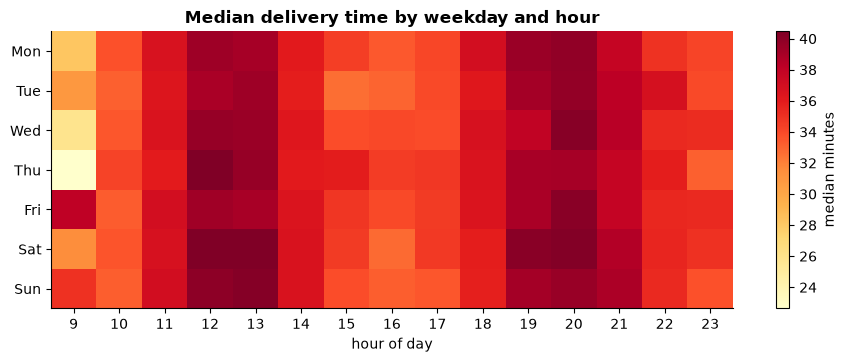

In [18]:
# Hour x weekday heatmap of the median delivery time (pivot_table + imshow)
heat = train.pivot_table(index="dow", columns="hour", values="delivery_minutes", aggfunc="median")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(7)); ax.set_yticklabels(days)
ax.set_xlabel("hour of day"); ax.grid(False)
fig.colorbar(im, ax=ax, label="median minutes")
ax.set_title("Median delivery time by weekday and hour")
plt.show()
savefig(fig, "03_hour_weekday_heatmap")

**What the EDA tells us:** delivery time depends on the **hour** (lunch and dinner peaks), **distance**, **rain**, **kitchen load** and **basket size**. These are exactly the features we built, so a model has real signal to learn.

# 6. Models

In [19]:
FEATURES = ["distance_km", "dist_sq", "n_items", "kitchen_load_30m", "city_orders_15m", "items_x_load",
            "is_lunch", "is_dinner", "is_weekend", "hour_sin", "hour_cos",
            "rain_mm", "is_raining", "dist_x_rain", "dist_x_peak", "temp_c",
            "is_ev", "is_scooter", "exp_months_capped", "rest_rating", "reported_prep_min", "rest_hist_min", "order_value"]
CITY_DUMMIES = pd.get_dummies(train["city"], drop_first=True, dtype=float).columns.tolist()

def design(d, mean=None, std=None):
    X = d[FEATURES].astype(float).copy()
    for col in CITY_DUMMIES:
        X[col] = (d["city"] == col).astype(float)
    if mean is None:
        mean, std = X.mean(), X.std().replace(0, 1)
    return (X - mean) / std, mean, std

X_train, mu, sd = design(train)
X_valid, _, _ = design(valid, mu, sd)
X_test, _, _ = design(test, mu, sd)
y_train, y_valid, y_test = (d["delivery_minutes"].to_numpy() for d in (train, valid, test))
print("design matrix:", X_train.shape, "(features were standardized with TRAIN mean and std)")

design matrix: (41195, 26) (features were standardized with TRAIN mean and std)


## 6.1 Metrics

In [20]:
def evaluate(y, pred):
    err = y - pred
    return {
        "MAE (min)": np.abs(err).mean(),
        "RMSE (min)": np.sqrt((err ** 2).mean()),
        "R2": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
        "within 5 min %": (np.abs(err) <= 5).mean() * 100,
        "within 10 min %": (np.abs(err) <= 10).mean() * 100,
    }

## 6.2 Baselines (the model must beat them)

1. **Flat promise**: always predict the training mean (what the app does today, roughly).
2. **Hour mean**: the average of each hour of the day.
3. **Distance line**: a straight line through distance only (`np.polyfit`).

In [21]:
rows = {}
rows["flat: training mean"] = evaluate(y_valid, np.full(len(y_valid), y_train.mean()))

hour_mean = train.groupby("hour")["delivery_minutes"].mean()
rows["hour-of-day mean"] = evaluate(y_valid, valid["hour"].map(hour_mean).to_numpy())

slope, intercept = np.polyfit(train["distance_km"], y_train, 1)
rows["distance only (line)"] = evaluate(y_valid, intercept + slope * valid["distance_km"].to_numpy())

pd.DataFrame(rows).T.round(2)

,MAE (min),RMSE (min),R2,within 5 min %,within 10 min %
flat: training mean,7.94,10.62,-0.00,39.86,70.52
hour-of-day mean,7.75,10.39,0.04,40.91,72.04
distance only (line),6.23,8.79,0.31,51.17,82.37


## 6.3 Ridge regression from scratch

Linear regression finds weights `w` that minimise the squared error. **Ridge** adds a penalty `lambda * ||w||²` that keeps the weights small, which helps when features are correlated (distance and distance², load and items x load).

It has a **closed-form solution**, no gradient descent needed:

```
w = (XᵀX + λI)⁻¹ Xᵀy       -> solved with  np.linalg.solve(XᵀX + λI, Xᵀy)
```
The intercept is **not** penalised (we centre the target instead).

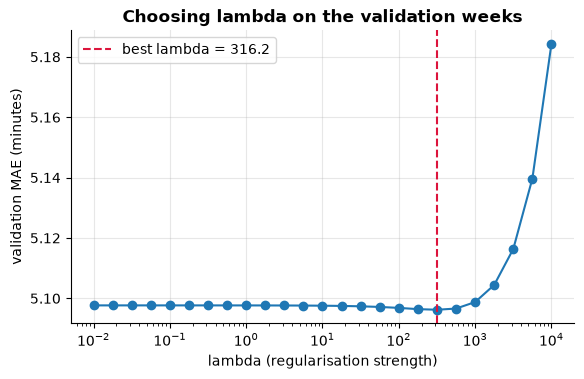

In [22]:
class RidgeScratch:
    def __init__(self, lam=1.0):
        self.lam = lam

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.y_mean = y.mean()
        A = X.T @ X + self.lam * np.eye(X.shape[1])
        self.w = np.linalg.solve(A, X.T @ (y - self.y_mean))        # solve() is faster and more stable than inv()
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.y_mean

# Choose lambda on the VALIDATION weeks (never on the test weeks)
lams = np.logspace(-2, 4, 25)
val_mae = [np.abs(y_valid - RidgeScratch(l).fit(X_train, y_train).predict(X_valid)).mean() for l in lams]
best_lam = lams[int(np.argmin(val_mae))]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(lams, val_mae, marker="o", color="#1f77b4")
ax.axvline(best_lam, color="crimson", linestyle="--", label=f"best lambda = {best_lam:.1f}")
ax.set_xlabel("lambda (regularisation strength)"); ax.set_ylabel("validation MAE (minutes)")
ax.set_title("Choosing lambda on the validation weeks"); ax.legend()
plt.show()
savefig(fig, "04_lambda_validation")

In [23]:
ridge = RidgeScratch(best_lam).fit(X_train, y_train)
rows["ridge (all features)"] = evaluate(y_valid, ridge.predict(X_valid))
pd.DataFrame(rows).T.round(2)

,MAE (min),RMSE (min),R2,within 5 min %,within 10 min %
flat: training mean,7.94,10.62,-0.00,39.86,70.52
hour-of-day mean,7.75,10.39,0.04,40.91,72.04
distance only (line),6.23,8.79,0.31,51.17,82.37
ridge (all features),5.10,7.55,0.49,61.44,90.71


## 6.4 Model the log of the time

Delivery times are **right-skewed** (a few very slow orders). Predicting `log(minutes)` often fits better, because errors become **relative** (10% of the time) instead of absolute. We predict the log and convert back with `exp`.

In [24]:
ridge_log = RidgeScratch(best_lam).fit(X_train, np.log(y_train))
pred_log = np.exp(ridge_log.predict(X_valid))
rows["ridge on log(minutes)"] = evaluate(y_valid, pred_log)

comparison = pd.DataFrame(rows).T.round(2)
comparison

,MAE (min),RMSE (min),R2,within 5 min %,within 10 min %
flat: training mean,7.94,10.62,-0.00,39.86,70.52
hour-of-day mean,7.75,10.39,0.04,40.91,72.04
distance only (line),6.23,8.79,0.31,51.17,82.37
ridge (all features),5.10,7.55,0.49,61.44,90.71
ridge on log(minutes),5.04,7.61,0.49,63.48,89.99


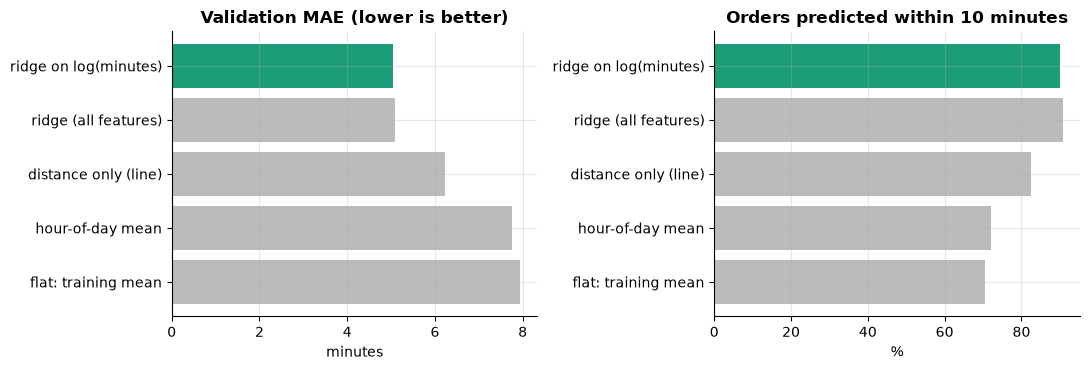

In [25]:
# Compare the models side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
order = comparison.sort_values("MAE (min)", ascending=False)
colors = ["#bbbbbb"] * (len(order) - 1) + ["#1b9e77"]
axes[0].barh(order.index, order["MAE (min)"], color=colors)
axes[0].set_title("Validation MAE (lower is better)"); axes[0].set_xlabel("minutes")
axes[1].barh(order.index, order["within 10 min %"], color=colors)
axes[1].set_title("Orders predicted within 10 minutes"); axes[1].set_xlabel("%")
plt.tight_layout(); plt.show()
savefig(fig, "05_model_comparison")

## 6.5 Final model and the honest test

We pick the best variant on the **validation** weeks, then **refit it on train + validation** (more recent data) and measure on the **test weeks once**.

In [26]:
use_log = comparison.loc["ridge on log(minutes)", "MAE (min)"] < comparison.loc["ridge (all features)", "MAE (min)"]
print("final model uses log target:", use_log)

trval = pd.concat([train, valid])
# restaurant history for the combined data: recompute leave-one-out on train+valid, and the table for test
g_sum = trval.groupby("restaurant_id")["delivery_minutes"].transform("sum")
g_cnt = trval.groupby("restaurant_id")["delivery_minutes"].transform("count")
global_mean = trval["delivery_minutes"].mean()
trval["rest_hist_min"] = smooth(g_sum - trval["delivery_minutes"], g_cnt - 1)
stats = trval.groupby("restaurant_id")["delivery_minutes"].agg(["sum", "count"])
test["rest_hist_min"] = test["restaurant_id"].map(smooth(stats["sum"], stats["count"])).fillna(global_mean)

X_trval, mu2, sd2 = design(trval)
X_test2, _, _ = design(test, mu2, sd2)
y_trval = trval["delivery_minutes"].to_numpy()

if use_log:
    final = RidgeScratch(best_lam).fit(X_trval, np.log(y_trval))
    pred_test = np.exp(final.predict(X_test2))
else:
    final = RidgeScratch(best_lam).fit(X_trval, y_trval)
    pred_test = final.predict(X_test2)

test_rows = {
    "flat: training mean": evaluate(y_test, np.full(len(y_test), y_trval.mean())),
    "hour-of-day mean": evaluate(y_test, test["hour"].map(trval.groupby("hour")["delivery_minutes"].mean()).to_numpy()),
    "FINAL ridge": evaluate(y_test, pred_test),
}
pd.DataFrame(test_rows).T.round(2)

final model uses log target: True


,MAE (min),RMSE (min),R2,within 5 min %,within 10 min %
flat: training mean,7.81,10.27,-0.00,38.74,71.63
hour-of-day mean,7.60,10.02,0.05,40.35,72.84
FINAL ridge,4.88,7.16,0.51,63.76,90.98


---
# 7. Where is the model wrong? (error analysis)

A single MAE hides the story. We look at **when and where** the errors are large.

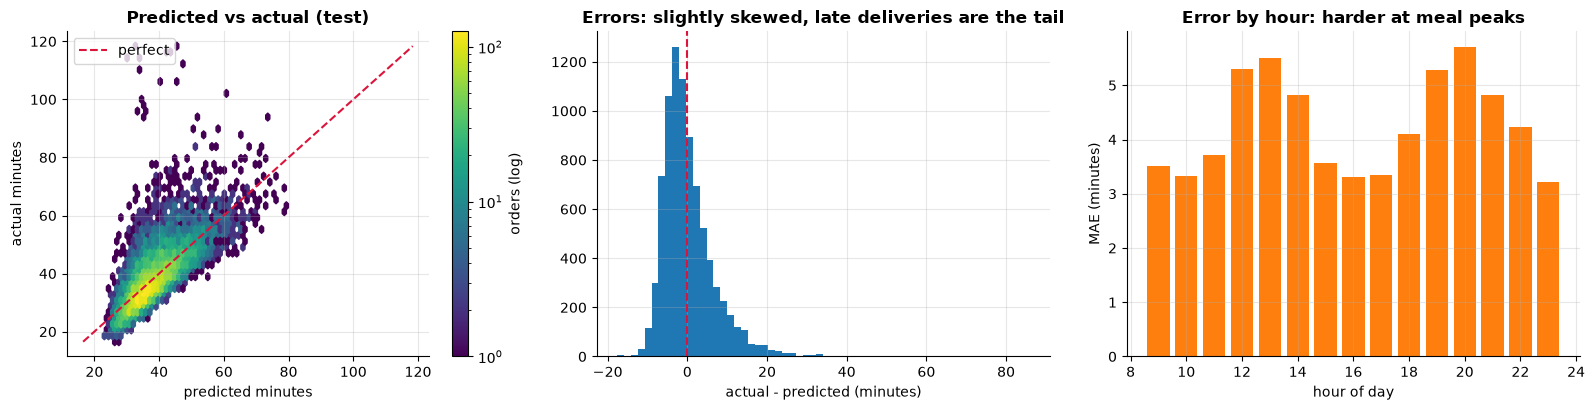

In [27]:
test = test.assign(pred=pred_test, error=y_test - pred_test, abs_error=np.abs(y_test - pred_test))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

hb = axes[0].hexbin(test["pred"], test["delivery_minutes"], gridsize=45, cmap="viridis", mincnt=1, bins="log")
lims = [test["delivery_minutes"].min(), test["delivery_minutes"].max()]
axes[0].plot(lims, lims, "--", color="crimson", label="perfect")
axes[0].set_xlabel("predicted minutes"); axes[0].set_ylabel("actual minutes"); axes[0].legend()
axes[0].set_title("Predicted vs actual (test)")
fig.colorbar(hb, ax=axes[0], label="orders (log)")

axes[1].hist(test["error"], bins=60, color="#1f77b4")
axes[1].axvline(0, color="crimson", linestyle="--")
axes[1].set_xlabel("actual - predicted (minutes)")
axes[1].set_title("Errors: slightly skewed, late deliveries are the tail")

mae_h = test.groupby("hour")["abs_error"].mean()
axes[2].bar(mae_h.index, mae_h.values, color="#ff7f0e")
axes[2].set_xlabel("hour of day"); axes[2].set_ylabel("MAE (minutes)")
axes[2].set_title("Error by hour: harder at meal peaks")
plt.tight_layout(); plt.show()
savefig(fig, "06_error_analysis")

In [28]:
seg = pd.concat([
    test.groupby(pd.cut(test["distance_km"], [0, 1, 2, 3, 4, 12]), observed=True)["abs_error"].agg(["mean", "count"]).rename_axis("segment").reset_index().assign(group="distance km"),
    test.groupby("is_raining")["abs_error"].agg(["mean", "count"]).rename_axis("segment").reset_index().assign(group="raining"),
    test.groupby("city")["abs_error"].agg(["mean", "count"]).rename_axis("segment").reset_index().assign(group="city"),
], ignore_index=True)
seg["segment"] = seg["segment"].astype(str)
seg["MAE"] = seg["mean"].round(2)
seg[["group", "segment", "count", "MAE"]]

,group,segment,count,MAE
0,distance km,"(0, 1]",1155,4.80
1,distance km,"(1, 2]",2114,4.79
2,distance km,"(2, 3]",1879,4.71
3,distance km,"(3, 4]",1306,4.70
4,distance km,"(4, 12]",1887,5.32
5,raining,0,7601,4.78
6,raining,1,740,5.92
7,city,Bhopal,2037,4.91
8,city,Indore,2115,4.87
9,city,Jaipur,2075,4.88


Typically the model is least accurate for **long distances**, **rain** and **peak hours**, where the real delivery time is also the most random. A good report states this honestly. A fix is to add a **wider safety buffer** for those segments, which is exactly what the promise policy does next.

# 8. From ETA to a promise (the business decision)

The model predicts the **typical** time. A **promise** must be reliable. We add a safety buffer:

```
promise = predicted minutes + buffer
```
Target: **85% of orders on time** (delivered at or before the promise). Choose the buffer on the **validation** weeks, apply it on the **test** weeks.

In [29]:
# validation predictions of the final-type model (trained on train only, as in section 6)
if use_log:
    pred_valid = np.exp(ridge_log.predict(X_valid))
else:
    pred_valid = ridge.predict(X_valid)

TARGET_ON_TIME = 0.85
resid_valid = y_valid - pred_valid
buffer = np.quantile(resid_valid, TARGET_ON_TIME)                       # 85th percentile of (actual - predicted)
print(f"buffer for {TARGET_ON_TIME:.0%} on time: +{buffer:.1f} minutes")

# the flat promise that reaches the same on-time rate on validation
flat_minutes = np.quantile(y_valid, TARGET_ON_TIME)
print(f"flat promise for {TARGET_ON_TIME:.0%} on time: {flat_minutes:.0f} minutes for everyone")

buffer for 85% on time: +6.8 minutes
flat promise for 85% on time: 50 minutes for everyone


In [30]:
def policy_result(y, promise):
    return {"on-time %": (y <= promise).mean() * 100, "average promise (min)": np.mean(promise),
            "promise std (min)": np.std(promise)}

policies = {
    "flat promise (same for all)": policy_result(y_test, np.full(len(y_test), flat_minutes)),
    "model + one buffer": policy_result(y_test, pred_test + buffer),
}

# Segment-aware buffer: one buffer per weather x peak-time group (errors are larger when it rains or at meal peaks)
def seg_key(d):
    peak = (d["is_lunch"] | d["is_dinner"]).astype(int)
    return np.where(d["is_raining"] == 1, "rain", "dry") + " / " + np.where(peak == 1, "peak", "off-peak")

valid_seg = pd.Series(seg_key(valid), index=valid.index)
test_seg = pd.Series(seg_key(test), index=test.index)
seg_buffer = pd.Series(resid_valid, index=valid.index).groupby(valid_seg).quantile(TARGET_ON_TIME)
promise_seg = pred_test + test_seg.map(seg_buffer).astype(float).fillna(buffer).to_numpy()
policies["model + buffer per weather/peak group"] = policy_result(y_test, promise_seg)

print("buffers learned on validation (minutes):")
print(seg_buffer.round(1).to_dict())
pd.DataFrame(policies).T.round(1)

buffers learned on validation (minutes):
{'dry / off-peak': 5.0, 'dry / peak': 7.0, 'rain / off-peak': 7.3, 'rain / peak': 9.6}


,on-time %,average promise (min),promise std (min)
flat promise (same for all),85.9,49.7,0.0
model + one buffer,86.3,45.8,7.6
model + buffer per weather/peak group,86.2,45.8,8.0


At the **same on-time rate**, the model-based promise is **shorter on average** than the flat promise: short orders get a short promise (more orders won), long orders get an honest, longer promise (fewer late deliveries).

## The trade-off curve

Every policy trades **on-time rate** against **promise length**. A better predictor gives a better curve.

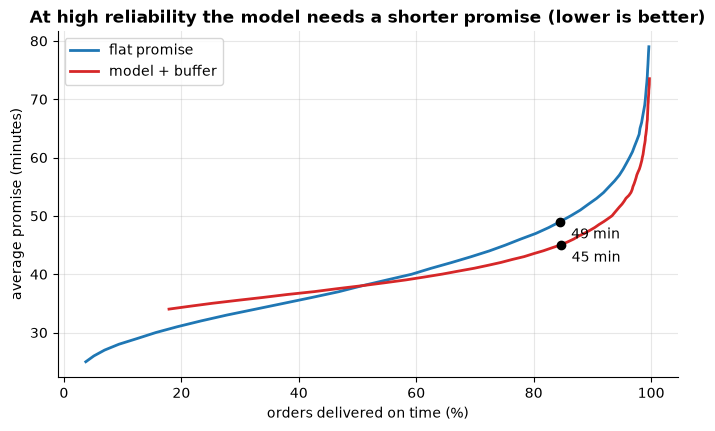

In [31]:
flat_grid = np.arange(25, 80, 1.0)
buf_grid = np.arange(-5, 35, 0.5)

flat_curve = np.array([[(y_test <= m).mean() * 100, m] for m in flat_grid])
model_curve = np.array([[(y_test <= pred_test + b).mean() * 100, (pred_test + b).mean()] for b in buf_grid])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(flat_curve[:, 0], flat_curve[:, 1], color="#1f77b4", linewidth=2, label="flat promise")
ax.plot(model_curve[:, 0], model_curve[:, 1], color="#d62728", linewidth=2, label="model + buffer")
ax.set_xlabel("orders delivered on time (%)"); ax.set_ylabel("average promise (minutes)")
ax.set_title("At high reliability the model needs a shorter promise (lower is better)")
ax.legend()
for label, p in [("flat", flat_curve), ("model", model_curve)]:
    i = np.argmin(np.abs(p[:, 0] - 85))
    ax.plot(p[i, 0], p[i, 1], "o", color="black")
    ax.annotate(f"{p[i, 1]:.0f} min", (p[i, 0], p[i, 1]), textcoords="offset points", xytext=(8, -12))
plt.show()
savefig(fig, "07_promise_tradeoff")

In [32]:
# Is the promise fair for every segment? On-time % by distance band (flat vs model) and by weather/peak group (one buffer vs group buffers)
chk = test.assign(on_time_flat=y_test <= flat_minutes, on_time_one=y_test <= pred_test + buffer,
                  on_time_seg=y_test <= promise_seg, seg=test_seg)
chk["dist_band"] = pd.cut(chk["distance_km"], [0, 1, 2, 3, 4, 12]).astype(str)

by_dist = chk.groupby("dist_band")[["on_time_flat", "on_time_one"]].mean().mul(100).round(1)
by_dist.columns = ["flat promise", "model + one buffer"]
print("On-time % by distance band")
print(by_dist, "\n")

by_seg = chk.groupby("seg")[["on_time_flat", "on_time_one", "on_time_seg"]].mean().mul(100).round(1)
by_seg.columns = ["flat promise", "model + one buffer", "model + group buffers"]
by_seg["orders"] = chk.groupby("seg").size()
print("On-time % by weather / peak group")
print(by_seg)

On-time % by distance band
           flat promise  model + one buffer
dist_band                                  
(0, 1]             96.8                87.2
(1, 2]             94.9                86.0
(2, 3]             92.5                86.6
(3, 4]             86.9                86.3
(4, 12]            61.6                85.9 

On-time % by weather / peak group
                 flat promise  model + one buffer  model + group buffers  orders
seg                                                                             
dry / off-peak           94.4                92.0                   88.4    1710
dry / peak               84.7                85.1                   85.5    5891
rain / off-peak          84.5                83.2                   85.5     220
rain / peak              71.5                82.3                   87.3     520


- The **flat promise** is far too tight for long distances (many late deliveries) and too loose for short ones: it is not fair to anyone.
- **Model + one buffer** is much more even across distances, because the model already knows the distance.
- The remaining differences are between **weather and peak groups**, where the prediction error is larger. A **buffer per group** moves each group closer to the 85% target. This is a simple version of **quantile regression** (predicting the 85th percentile directly), the natural next step in a real system.

**Say it in an interview:** "The model predicts the mean, but the business needs a reliable promise. I added a buffer equal to the 85th percentile of validation residuals, tried one buffer and a buffer per risk group, and compared policies on the test weeks on two axes: on-time rate and average promise length. The flat promise was dominated."

---
# 9. Save the deliverables

In [33]:
df.drop(columns=["hour_ts"]).to_csv(DATA / "orders_clean_features.csv", index=False)
test[["order_id", "placed_at", "city", "distance_km", "delivery_minutes", "pred", "abs_error"]].to_csv(DATA / "test_predictions.csv", index=False)

card = {
    "task": "predict delivery minutes at order time",
    "model": "ridge regression (NumPy closed form)" + (" on log(minutes)" if use_log else ""),
    "lambda": round(float(best_lam), 3),
    "split": {"train_weeks": "1-10", "validation_weeks": "11-12", "test_weeks": "13-14"},
    "test_metrics": {k: round(float(v), 3) for k, v in evaluate(y_test, pred_test).items()},
    "promise_buffer_min": round(float(buffer), 2), "target_on_time": TARGET_ON_TIME,
    "excluded_leaky_columns": ["pickup_at", "delivered_at"],
}
(DATA / "model_card.json").write_text(json.dumps(card, indent=2))
print(json.dumps(card, indent=2))

{
  "task": "predict delivery minutes at order time",
  "model": "ridge regression (NumPy closed form) on log(minutes)",
  "lambda": 316.228,
  "split": {
    "train_weeks": "1-10",
    "validation_weeks": "11-12",
    "test_weeks": "13-14"
  },
  "test_metrics": {
    "MAE (min)": 4.88,
    "RMSE (min)": 7.163,
    "R2": 0.514,
    "within 5 min %": 63.757,
    "within 10 min %": 90.984
  },
  "promise_buffer_min": 6.76,
  "target_on_time": 0.85,
  "excluded_leaky_columns": [
    "pickup_at",
    "delivered_at"
  ]
}


---
# 10. Summary, resume bullets, interview questions

In [34]:
m = evaluate(y_test, pred_test)
flat = policies["flat promise (same for all)"]; mod = policies["model + one buffer"]; grp = policies["model + buffer per weather/peak group"]
print("RESULTS (test weeks 13-14, never used for any decision)")
print(f"  MAE {m['MAE (min)']:.1f} min | RMSE {m['RMSE (min)']:.1f} | R2 {m['R2']:.2f} | within 10 min {m['within 10 min %']:.0f}%")
print(f"  baseline (flat mean) MAE {test_rows['flat: training mean']['MAE (min)']:.1f} min")
print(f"  flat promise: {flat['average promise (min)']:.0f} min at {flat['on-time %']:.0f}% on time | model promise: {mod['average promise (min)']:.0f} min at {mod['on-time %']:.0f}%")

print("\nRESUME BULLETS (use your own numbers)")
print(f"- Built a delivery-time predictor for a food delivery app on 58,000 orders across 4 cities: merged 4 raw tables, engineered haversine distance, kitchen-load (NumPy searchsorted) and weather features, and used a time-based train/validation/test split.")
print(f"- Implemented ridge regression from scratch with NumPy (closed form), reducing MAE from {test_rows['flat: training mean']['MAE (min)']:.1f} to {m['MAE (min)']:.1f} minutes versus a flat baseline.")
print(f"- Designed a promise policy (prediction + validation-quantile buffer) that kept {mod['on-time %']:.0f}% on-time while shortening the average promise by {flat['average promise (min)'] - mod['average promise (min)']:.1f} minutes versus a flat promise.")

RESULTS (test weeks 13-14, never used for any decision)
  MAE 4.9 min | RMSE 7.2 | R2 0.51 | within 10 min 91%
  baseline (flat mean) MAE 7.8 min
  flat promise: 50 min at 86% on time | model promise: 46 min at 86%

RESUME BULLETS (use your own numbers)
- Built a delivery-time predictor for a food delivery app on 58,000 orders across 4 cities: merged 4 raw tables, engineered haversine distance, kitchen-load (NumPy searchsorted) and weather features, and used a time-based train/validation/test split.
- Implemented ridge regression from scratch with NumPy (closed form), reducing MAE from 7.8 to 4.9 minutes versus a flat baseline.
- Designed a promise policy (prediction + validation-quantile buffer) that kept 86% on-time while shortening the average promise by 3.9 minutes versus a flat promise.


## Likely interview questions about this project

**1. Which columns did you exclude and why?**
`pickup_at` and `delivered_at`: they are known only after the order. Using them is target leakage. I also treated the rider as known and mentioned that in production the assigned rider is not yet known at promise time.

**2. Why a time-based split?**
The model predicts the future. Random splits mix weeks, and features such as kitchen load and weather are time dependent. Validation weeks choose lambda, test weeks are touched once.

**3. Why ridge regression, and why standardise?**
Features are correlated (distance and distance squared). The L2 penalty stabilises the weights. Standardising puts all features on the same scale so the penalty treats them fairly.

**4. Why model the log of the delivery time?**
The target is right-skewed. The log makes errors relative, reduces the pull of very slow orders and usually improves MAE. Predictions are converted back with `exp`.

**5. How did you compute kitchen load efficiently?**
A sortable key `restaurant * 1e8 + seconds`, sorted once, then two `np.searchsorted` calls give the count of earlier orders inside the window. I verified it against a slow loop on a sample. That is O(n log n) instead of O(n squared).

**6. How did you treat outliers (stuck orders)?**
I flagged orders over 120 minutes instead of deleting them silently. They are a different failure mode (incidents), handled separately, and excluded from the ETA model.

**7. How do you go from a prediction to a promise?**
Promise = prediction + buffer, where the buffer is a quantile of validation residuals for the target on-time rate. A buffer per distance band evens out reliability. A direct alternative is quantile regression.

**8. What is target encoding and how did you avoid leakage with it?**
I replaced the restaurant by its historical average delivery time, learned from training weeks only, smoothed towards the global mean, and used leave-one-out for the training rows.

**9. What would you do next?**
Gradient boosting, quantile regression, live features (current rider supply, real traffic), and an A/B test of the new promise measuring orders, late rate and complaints.

**10. How would you monitor it in production?**
Track MAE and on-time rate by city, hour and distance every day, and alert on drift in the residual quantiles (a rising 85th percentile means promises are becoming unreliable).

## Extension ideas

1. Predict the **85th percentile directly** with a pinball (quantile) loss in NumPy.
2. Add **rider supply and demand** per zone as features.
3. Use `sklearn.ensemble.HistGradientBoostingRegressor` and compare MAE and feature importance.
4. Build a **Streamlit** page where you enter an order and see the promise (your folder `21_streamlit`).
5. Wrap the model in a **FastAPI** endpoint `/eta` (your folder `22_fast_api`).

## Revision sheet: functions you practised

| Library | Functions and ideas |
|---|---|
| **pandas** | `merge` on several keys with `validate`, `to_datetime` two-pass, `dt.floor`, `reindex` + `ffill` + `interpolate`, `groupby().transform`, `pivot_table`, `cut`, `map`, `quantile`, `get_dummies`, `assign`, boolean masks |
| **NumPy** | `radians`, `sin`, `arcsin`, `sqrt` (haversine), `argsort`, `searchsorted`, `linalg.solve`, `eye`, `@`, `logspace`, `quantile`, `polyfit`, `hypot`-style distance, broadcasting |
| **Matplotlib** | `fill_between`, `boxplot`, `hexbin`, `imshow`, `semilogx`, `barh`, `annotate`, `colorbar`, subplots |
| **ML ideas** | leakage, time-based split, standardisation, ridge, log target, baselines, error analysis, quantile buffer, trade-off curve |